# Review 2 — Method 2

Member 2 Part A: corpus, tone, complexity and interpretation. **Member 4 Part B (topics and keywords) is supplied separately. Human labels remain an explicit dependency.**

In [1]:
from pathlib import Path
import json, pandas as pd
from IPython.display import display, Image
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'config.yaml').exists())


## Corpus preparation and audit

In [2]:
TEXT=ROOT/'reports/review2/text'
assert json.loads((TEXT/'corpus_stats.json').read_text())['documents_after']==302026
display(json.loads((TEXT/'corpus_stats.json').read_text()))
display(json.loads((TEXT/'text_preprocessing.json').read_text()))
display(pd.read_parquet(TEXT/'corpus_sample_metadata.parquet').head(8))

{'documents_before': 302026,
 'documents_after': 302026,
 'empty_after_cleaning': 0,
 'vocabulary_size': 165887,
 'total_tokens': 14312333,
 'spacy_model': 'en_core_web_sm',
 'parser_ner': 'disabled',
 'code_excluded': True,
 'sampling_weight': 'retained, must be used in shares',
 'seconds': 418.75}

{'technology_tokens': {'c++': 'cplusplus',
  'c#': 'csharp',
  '.net': 'dotnet',
  'node.js': 'nodejs',
  'next.js': 'nextjs',
  'vue.js': 'vuejs',
  'asp.net': 'aspnet'},
 'stopwords': ["'d",
  "'ll",
  "'m",
  "'re",
  "'s",
  "'ve",
  'a',
  'about',
  'above',
  'across',
  'after',
  'afterwards',
  'again',
  'against',
  'all',
  'almost',
  'alone',
  'along',
  'already',
  'also',
  'although',
  'always',
  'am',
  'among',
  'amongst',
  'amount',
  'an',
  'and',
  'another',
  'any',
  'anyhow',
  'anyone',
  'anything',
  'anyway',
  'anywhere',
  'are',
  'around',
  'as',
  'at',
  'back',
  'be',
  'became',
  'because',
  'become',
  'becomes',
  'becoming',
  'been',
  'before',
  'beforehand',
  'behind',
  'being',
  'below',
  'beside',
  'besides',
  'between',
  'beyond',
  'both',
  'bottom',
  'but',
  'by',
  'ca',
  'call',
  'can',
  'cannot',
  'could',
  'did',
  'do',
  'does',
  'doing',
  'done',
  'down',
  'due',
  'during',
  'each',
  'eight',
  '

,question_id,created_at,tags,sampling_weight,target_resolved_7d,period,n_tokens,title,link
0,76680934,2023-07-13 15:09:46+00:00,"[powerbi, slicers]",1.0,0,post,29,How to auto select other 2 in a slicer when I ...,https://stackoverflow.com/q/76680934
1,61554380,2020-05-02 04:15:43+00:00,"[r, machine-learning, split, sample-data]",10.0,0,pre,41,How to sample small set of images for training...,https://stackoverflow.com/q/61554380
2,63254502,2020-08-04 20:20:18+00:00,"[javascript, reactjs, redux, react-redux, mern]",21.0,1,pre,47,Creating a put api request using Redux,https://stackoverflow.com/q/63254502
3,70956590,2022-02-02 13:35:23+00:00,"[python, seaborn]",20.0,0,pre,18,Highlight elements on heatmap using Python,https://stackoverflow.com/q/70956590
4,63107357,2020-07-27 01:02:02+00:00,"[javascript, r, shiny]",23.0,1,pre,23,How to force shiny input to be capitalized,https://stackoverflow.com/q/63107357
5,66844549,2021-03-28 18:03:13+00:00,"[javascript, html5-audio, web-audio-api]",8.0,1,pre,35,Muting sound output when using Mic - Audio Web...,https://stackoverflow.com/q/66844549
6,75992973,2023-04-12 07:32:16+00:00,"[sql, pyspark, etl, aws-glue, predicate]",20.0,0,post,43,Pushdown predicate between two date ranges if ...,https://stackoverflow.com/q/75992973
7,79653142,2025-06-04 16:11:52+00:00,"[android, kotlin, android-custom-view]",1.0,0,post,34,Visibility Attribute and onclick event not wor...,https://stackoverflow.com/q/79653142


## Tone on original prose, without code
Technical-word overrides are written down; lowercase clean topic text is not used for VADER.

In [3]:
display(json.loads((TEXT/'tone_method.json').read_text()))
display(pd.read_csv(TEXT/'tone_monthly.csv').head(10))
display(pd.read_csv(TEXT/'tone_prepost.csv').query("tag == 'ALL'"))

{'technical_word_overrides': ['kill',
  'fatal',
  'execute',
  'master',
  'abort',
  'dead',
  'failed',
  'exception',
  'error'],
 'frustration_regex': '\\burgent\\b|\\basap\\b|\\bstuck\\b|\\bfrustrat\\w*\\b|\\bfor (?:hours|days)\\b|\\bdesperate\\b|\\bnothing works\\b|\\bplease help\\b',
 'politeness_regex': '\\bthanks\\b|\\bthank you\\b|\\bappreciat\\w*\\b',
 'thresholds': {'positive': '>=0.05',
  'negative': '<=-0.05',
  'neutral': 'otherwise'},
 'label_rule': "Label the human asker's emotional tone as negative (expressed frustration/anger/distress), positive (expressed satisfaction/optimism/gratitude), or neutral (factual technical question without clear emotion). Technical error words alone are neutral. Do not use answer outcomes or the model score. Read the title and original question prose, ignoring code. Label independently before comparing.",
 'code_excluded': True,
 'warning': 'VADER is exploratory until independently human validated; no human labels are generated by code'

,tag,month,period,n_sampled,low_sample,negative_share,neutral_share,positive_share,frustration_flag_share,politeness_flag_share
0,ALL,2019-01,pre,4314,False,0.215858,0.080775,0.703367,0.043016,0.189923
1,ALL,2019-02,pre,4732,False,0.218167,0.070817,0.711016,0.059083,0.214329
2,ALL,2019-03,pre,4744,False,0.217897,0.081716,0.700387,0.042256,0.204239
3,ALL,2019-04,pre,4487,False,0.202331,0.078231,0.719438,0.043598,0.179721
4,ALL,2019-05,pre,4569,False,0.227093,0.072465,0.700443,0.047707,0.162119
5,ALL,2019-06,pre,4091,False,0.222263,0.080279,0.697458,0.040932,0.172883
6,ALL,2019-07,pre,4359,False,0.220875,0.075217,0.703908,0.039911,0.177244
7,ALL,2019-08,pre,4193,False,0.209912,0.072788,0.717301,0.045067,0.181804
8,ALL,2019-09,pre,3931,False,0.218215,0.082699,0.699086,0.044825,0.157295
9,ALL,2019-10,pre,4363,False,0.220997,0.079351,0.699652,0.049381,0.192348


,tag,measure,pre,post,change,lower95,upper95,bootstrap_resamples
0,ALL,negative,0.209487,0.236663,0.027176,0.021937,0.032179,1000
1,ALL,neutral,0.079173,0.072314,-0.006858,-0.009828,-0.003590,1000
2,ALL,positive,0.711341,0.691023,-0.020318,-0.025603,-0.015084,1000
3,ALL,frustration,0.050643,0.048570,-0.002073,-0.004611,0.000360,1000
4,ALL,politeness,0.208315,0.178995,-0.029320,-0.033888,-0.024433,1000


## Tone validation and annotation provenance
VADER is scored against the existing M3 human labels. Additional AI annotations are disclosed separately; human–AI kappa is not two-human agreement. No adjudicated gold standard is claimed.

In [4]:
status=json.loads((TEXT/'tone_validation_status.json').read_text())
display(status)
display(pd.read_csv(TEXT/'tone_validation.csv'))
if status.get('accuracy') is not None:
    display(pd.read_csv(TEXT/'tone_confusion.csv'))
print('Use frustration flags as an exploratory proxy; VADER is weak against the single-human reference.')
if (TEXT/'topic_naming_comparison.csv').exists():
    display(pd.read_csv(TEXT/'topic_naming_comparison.csv'))
    display(json.loads((TEXT/'topic_naming_status.json').read_text()))

{'required_rows': 200,
 'label_m2': 0,
 'label_m3': 200,
 'agreed_tone': 0,
 'accuracy': 0.36,
 'macro_f1': 0.34415857927121324,
 'cohen_kappa': None,
 'human_human_kappa': None,
 'original_two_human_requirement_complete': False,
 'status': 'complete_ai_assisted',
 'labelled_rows': 200,
 'label_ai': 200,
 'reference': 'Akshay/M3 single-human labels; no adjudicated gold standard',
 'ai_human_kappa': 0.2139983157106765,
 'ai_human_agreement': 0.58,
 'ai_macro_f1_vs_human': 0.41704845687077197,
 'annotation_file_sha256': '323267f6fd2e03208247db6a243bbd2268b059c68554fea100d6a545087868fc',
 'limitation': 'AI annotation is not a second independent human rating. Original two-human kappa/adjudication remains unavailable.'}

,required_rows,label_m2,label_m3,agreed_tone,accuracy,macro_f1,cohen_kappa,human_human_kappa,original_two_human_requirement_complete,status,labelled_rows,label_ai,reference,ai_human_kappa,ai_human_agreement,ai_macro_f1_vs_human,annotation_file_sha256,limitation
0,200,0,200,0,0.36,0.344159,NaN,NaN,False,complete_ai_assisted,200,200,Akshay/M3 single-human labels; no adjudicated ...,0.213998,0.58,0.417048,323267f6fd2e03208247db6a243bbd2268b059c68554fe...,AI annotation is not a second independent huma...


,actual,negative,neutral,positive
0,negative,29,0,33
1,neutral,32,8,60
2,positive,2,1,35


Use frustration flags as an exploratory proxy; VADER is weak against the single-human reference.


,topic,name_m4,name_m2,final_name,name_ai,rationale,comparison_note,annotation_source
0,0,Python Execution & Runtime Errors,NaN,Python Execution & Runtime Errors,"Runtime, package and API error troubleshooting","Python, package, API, script and server terms;...",Broad match; M4 wording overstates Python excl...,Codex AI assistant; not independent human M2
1,1,Pandas Dataframe & Data Manipulation,NaN,Pandas Dataframe & Data Manipulation,"Dataframe rows, columns and transformations",Column/dataframe/row dominate; example titles ...,Broad match with Pandas and dataframe manipula...,Codex AI assistant; not independent human M2
2,2,"Time Series, Dates & Numeric Formatting",NaN,"Time Series, Dates & Numeric Formatting","Mixed numerical tables, date calculations and ...",Number placeholders dominate; examples span gr...,Partial match: mixed tabular calculations; tim...,Codex AI assistant; not independent human M2
3,3,"Web Frontend, DOM & User Events",NaN,"Web Frontend, DOM & User Events","User-interface controls, clicks and browser in...",Button/click/page/HTML/event terms and button ...,Broad match; includes automation and some nati...,Codex AI assistant; not independent human M2
4,4,Power BI DAX & Data Modeling,NaN,Power BI DAX & Data Modeling,"Relational tables, queries and Power BI measures","Power BI, query, SQL, filter and DAX terms; ex...",Broad match but SQL examples extend beyond Pow...,Codex AI assistant; not independent human M2
5,5,React UI & State Management,NaN,React UI & State Management,"React components, props, rendering and state",React/component/render/state/prop terms with R...,Strong semantic match.,Codex AI assistant; not independent human M2
6,6,"File I/O, CSV & Excel Data Export",NaN,"File I/O, CSV & Excel Data Export","File operations, paths and data import/export",File/read/folder/CSV/Excel/JSON terms; example...,Broad match; file operations extend beyond CSV...,Codex AI assistant; not independent human M2
7,7,Docker Containers & Cloud Deployment,NaN,Docker Containers & Cloud Deployment,"Docker images, containers and Compose networking",Docker/image/container/compose/build terms; ex...,Broad match; cloud deployment is not establish...,Codex AI assistant; not independent human M2
8,8,"Core Syntax, Arrays & Data Structures",NaN,"Core Syntax, Arrays & Data Structures","Programming collections, functions and object ...",Array/function/list/object/string/loop terms a...,Strong match with core syntax and data structu...,Codex AI assistant; not independent human M2
9,9,Android Mobile App & Gradle Build,NaN,Android Mobile App & Gradle Build,"Android development, devices and build configu...",Android/app/Java/Gradle/studio terms with buil...,Broad match; includes runtime and device conce...,Codex AI assistant; not independent human M2


{'status': 'complete_ai_assisted',
 'topics': 10,
 'human_m2_names': 0,
 'ai_names': 10,
 'interpretation': 'AI naming and qualitative comparison with M4-provided names',
 'original_two_human_requirement_complete': False,
 'human_naming_agreement': None,
 'limitation': 'AI names are disclosed assistance, not independent human M2 labels. M4 names were visible during the earlier repository audit; the topic comparison is not blind or a human agreement estimate.'}

## Complexity and weighted pre/post uncertainty
Flesch is a prose-reading proxy and technical vocabulary can limit interpretation. Empty prose is not assigned a readability score.

{'readability': 'textstat Flesch reading ease on prose only; technical vocabulary limits interpretation',
 'bootstrap': '1000 question resamples with replacement; retain sampling_weight; compressed identical value/weight cells',
 'periods': 'pre <= 2022-10, transition 2022-11/12 excluded from contrast, post >= 2023-01',
 'flags': 'case-insensitive error; leading why/how; dotted numeric version; >=2 study tags',
 'empty_prose': 'Flesch undefined (NaN), not zero',
 'low_sample': 'monthly flag for <30 sampled questions'}

,tag,metric,statistic,pre,post,change,lower95,upper95,n_pre,n_post,bootstrap_resamples
0,ALL,prose_words,median,76.000000,89.000000,13.000000,12.000000,13.000000,207162,87619,1000
1,ALL,code_lines,median,16.000000,20.000000,4.000000,3.000000,4.000000,207162,87619,1000
2,ALL,n_code_blocks,median,1.000000,1.000000,0.000000,0.000000,1.000000,207162,87619,1000
3,ALL,tag_count,median,3.000000,3.000000,0.000000,0.000000,0.000000,207162,87619,1000
4,ALL,flesch_reading_ease,median,67.050000,64.540000,-2.510000,-2.700000,-2.320000,207162,87619,1000
5,ALL,error_text_flag,mean,0.234327,0.274250,0.039923,0.035075,0.045076,207162,87619,1000
6,ALL,why_how_flag,mean,0.260615,0.250686,-0.009928,-0.015069,-0.005014,207162,87619,1000
7,ALL,version_flag,mean,0.076325,0.105564,0.029239,0.025899,0.032733,207162,87619,1000
8,ALL,multi_technology_flag,mean,0.227622,0.194068,-0.033554,-0.038152,-0.028698,207162,87619,1000


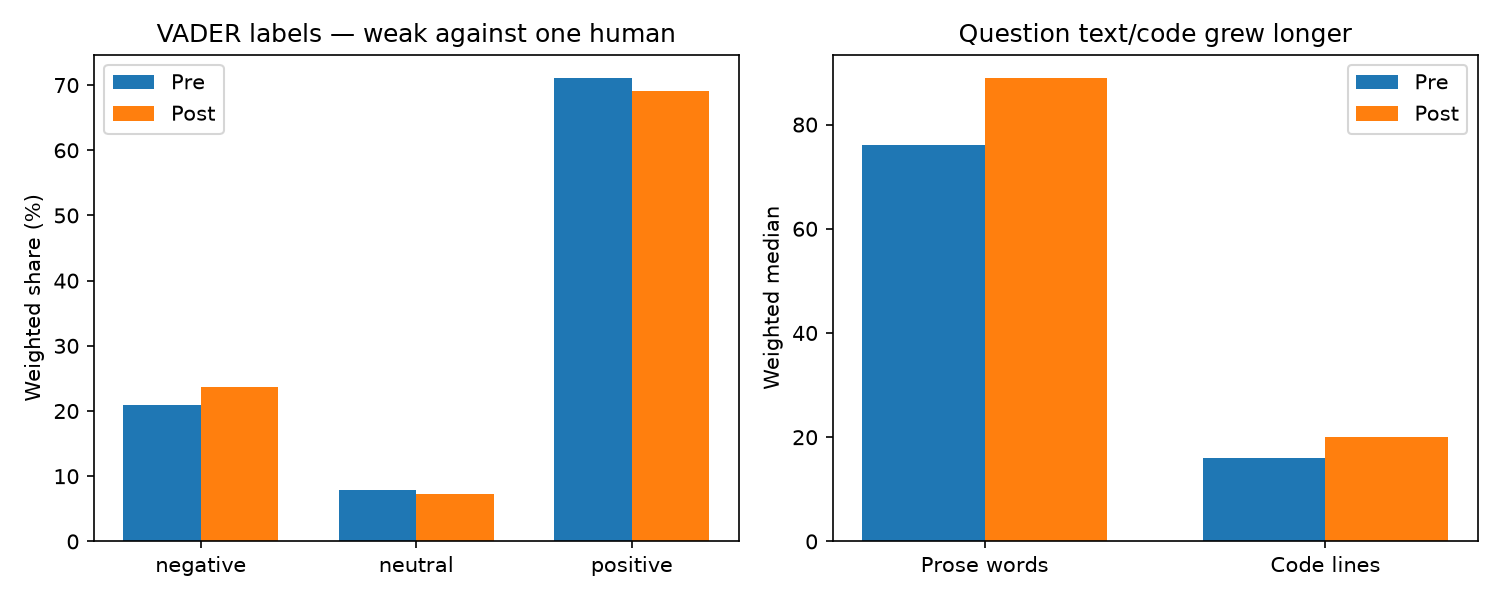

In [5]:
display(json.loads((TEXT/'complexity_method.json').read_text()))
display(pd.read_csv(TEXT/'complexity_prepost.csv').query("tag == 'ALL'"))
display(Image(filename=str(TEXT/'tone_complexity.png')))

## Exploratory association with resolution
Weighted logistic regression controls for full study-tag indicators and year. The coefficients are associations, not causal effects.

In [6]:
display(pd.read_csv(TEXT/'tone_resolution_association.csv'))

,term,coefficient,odds_ratio,lower95,upper95,p_value
0,const,-0.285507,0.751633,0.716941,0.788005,2.375759e-32
1,negative,0.009457,1.009501,0.972887,1.047494,6.158839e-01
2,positive,0.117569,1.124760,1.087836,1.162936,5.072457e-12
3,frustration,-0.189152,0.827661,0.794662,0.862029,8.086101e-20
4,tag_android,-0.367772,0.692275,0.666041,0.719543,1.082109e-77
5,tag_docker,-0.365890,0.693579,0.651427,0.738459,2.717593e-30
6,tag_excel,-0.164189,0.848581,0.801962,0.897911,1.232411e-08
7,tag_fastapi,-0.270024,0.763361,0.724315,0.804513,6.795929e-24
8,tag_java,-0.135807,0.873011,0.841924,0.905246,2.119104e-13
9,tag_javascript,0.112624,1.119211,1.083290,1.156324,1.318443e-11


## Findings and handoff

In [7]:
print((ROOT/'reports/review2/m2_findings.md').read_text())
display(json.loads((TEXT/'dashboard_handoff.json').read_text()))

# Member 2: tone and complexity findings

- Prepared 302,026 prose-only documents; 0 are empty after cleaning, and vocabulary contains 165,887 terms.
- Weighted median prose length changed from 76 to 89 words; difference 13, with 95% question-bootstrap interval [12, 13].
- Weighted median code lines changed from 16 to 20; difference 4, with 95% interval [3, 4].
- The written frustration-phrase flag changed from 5.1% to 4.9%; this is a lexicon measure, not independently verified emotion.
- Questions with at least two study tags changed from 22.8% to 19.4%; share-change 95% interval [-3.82, -2.87] percentage points.

VADER against M3's single-human reference: accuracy 36.0%, macro-F1 0.344. Human–AI kappa 0.214; this is not two-human validation.

Use frustration flags as the primary exploratory tone proxy; they are not a validated emotion classifier. AI annotations are explicitly disclosed. The original two-human agreement requirement remains unmet. Do not claim AI causality.



{'owner': 'M2 Rishiikesh',
 'schemas': {'topic_labels.csv': ['topic',
   'top_terms',
   'name_m4',
   'name_m2',
   'final_name',
   'agreement'],
  'complexity_monthly.csv': ['tag',
   'month',
   'period',
   'n_sampled',
   'low_sample',
   'prose_words_median',
   'code_lines_median',
   'n_code_blocks_median',
   'tag_count_median',
   'flesch_reading_ease_median',
   'error_text_flag_share',
   'why_how_flag_share',
   'version_flag_share',
   'multi_technology_flag_share'],
  'topic_ai_annotations.csv': ['topic',
   'name_ai',
   'rationale',
   'comparison_note',
   'annotation_source'],
  'topics_top_terms.csv': ['topic', 'rank', 'term', 'weight'],
  'tone_prepost.csv': ['tag',
   'measure',
   'pre',
   'post',
   'change',
   'lower95',
   'upper95',
   'bootstrap_resamples'],
  'dashboard_captions.csv': ['chart', 'file', 'takeaway', 'caveat'],
  'tone_ai_human_confusion.csv': ['human_m3',
   'negative',
   'neutral',
   'positive'],
  'complexity_prepost.csv': ['tag',
   '

## Part B — Nishanth’s topic models, shifts, and keyword dynamics

This section evaluates candidate topic models, model selection under the fixed rule, weighted pre/post topic share shifts with 1,000-resample bootstrap intervals, resolution outcomes, and Monroe et al. (2008) Dirichlet log-odds distinctive words.

### 1. Model Selection: NMF vs. LDA Across Candidate k
Pre-registered rule: pick the highest NPMI topic coherence on 20,000 held-out questions among candidates satisfying diversity $\ge 0.70$ and multi-seed stability $\ge 0.60$.

,model_family,k,coherence_npmi,diversity,stability,reconstruction_error,satisfies_rule,fit_seconds
0,NMF,10,0.2175,0.8000,1.0000,268.7,True,34.8
1,NMF,15,0.2041,0.7333,0.7881,267.0,True,42.9
2,NMF,20,0.1970,0.7000,0.8309,265.4,True,68.3
3,NMF,25,0.1988,0.6992,0.8501,264.1,False,57.9
4,NMF,30,0.1991,0.6827,0.8589,262.9,False,74.8
5,NMF,40,0.1948,0.6890,0.8360,260.8,False,211.1
6,LDA,10,-0.2065,0.8120,0.2837,NaN,False,33.8
7,LDA,15,-0.2504,0.8427,0.2152,NaN,False,33.4
8,LDA,20,-0.2576,0.7960,0.1911,NaN,False,37.5
9,LDA,25,-0.3351,0.8032,0.1949,NaN,False,41.3


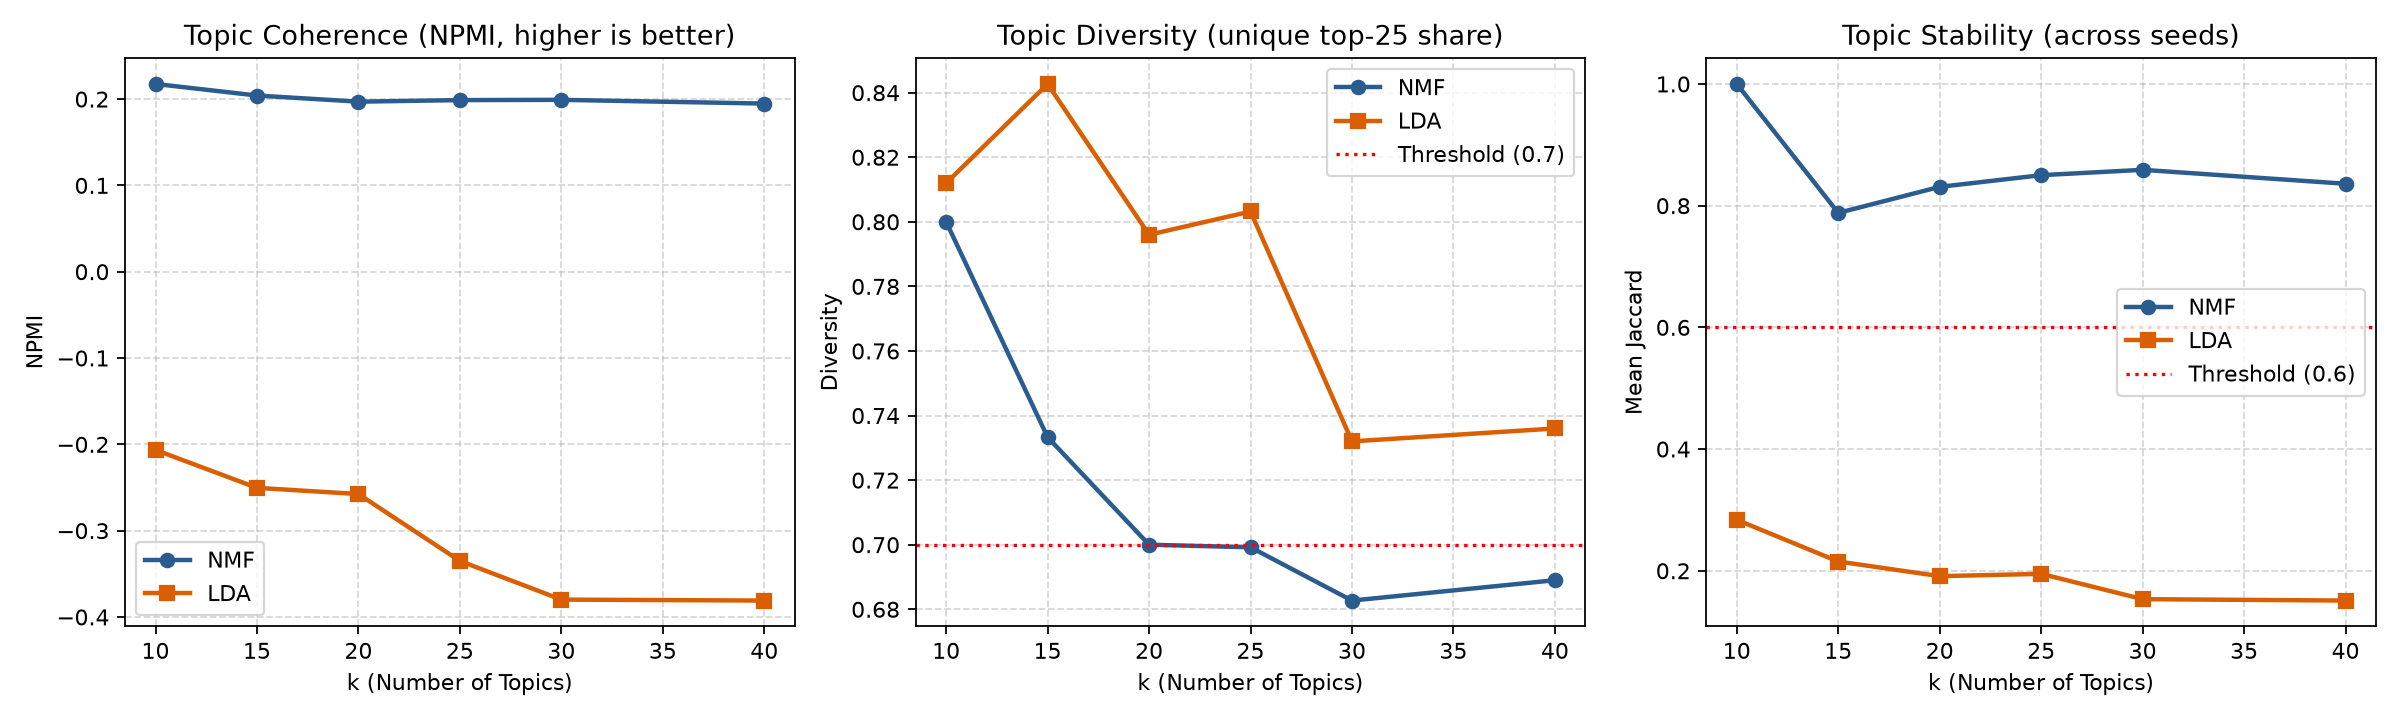

In [8]:
TEXT = ROOT / 'reports/review2/text'
selection_df = pd.read_csv(TEXT / 'topic_model_selection.csv')
display(selection_df)
display(Image(filename=str(TEXT / 'topic_model_selection.png')))

### 2. Winning Topic Model (NMF k=10): Top Terms & Human Naming Table
Top 15 terms per topic and Member 4 proposed names. Member 2 (Rishiikesh) column is reserved for independent double-blind human labeling.

In [9]:
display(pd.read_csv(TEXT / 'topics_top_terms.csv').head(20))
display(pd.read_csv(TEXT / 'topic_labels.csv'))

,topic,rank,term,weight
0,0,1,error,3.6642
1,0,2,run,1.6786
2,0,3,code,1.6679
3,0,4,python,1.5625
4,0,5,message,0.9560
5,0,6,request,0.9254
6,0,7,follow,0.8977
7,0,8,api,0.8192
8,0,9,test,0.7963
9,0,10,package,0.6537


,topic,top_terms,name_m4,name_m2,final_name,agreement
0,0,"error, run, code, python, message, request",Python Execution & Runtime Errors,NaN,Python Execution & Runtime Errors,pending_m2
1,1,"column, dataframe, row, value, panda, like",Pandas Dataframe & Data Manipulation,NaN,Pandas Dataframe & Data Manipulation,pending_m2
2,2,"numbertoken, numbertoken numbertoken, date, ye...","Time Series, Dates & Numeric Formatting",NaN,"Time Series, Dates & Numeric Formatting",pending_m2
3,3,"button, click, page, user, html, text","Web Frontend, DOM & User Events",NaN,"Web Frontend, DOM & User Events",pending_m2
4,4,"table, power, date, bi, power bi, query",Power BI DAX & Data Modeling,NaN,Power BI DAX & Data Modeling,pending_m2
5,5,"component, react, render, js, state, prop",React UI & State Management,NaN,React UI & State Management,pending_m2
6,6,"file, csv, folder, read, excel, csv file","File I/O, CSV & Excel Data Export",NaN,"File I/O, CSV & Excel Data Export",pending_m2
7,7,"docker, image, container, run, compose, docker...",Docker Containers & Cloud Deployment,NaN,Docker Containers & Cloud Deployment,pending_m2
8,8,"array, function, list, value, object, string","Core Syntax, Arrays & Data Structures",NaN,"Core Syntax, Arrays & Data Structures",pending_m2
9,9,"android, app, java, build, device, studio",Android Mobile App & Gradle Build,NaN,Android Mobile App & Gradle Build,pending_m2


### 3. Representative Questions per Topic (Title & Original Link Only)
In compliance with CC BY-SA 4.0 license and privacy, only question titles and hyperlinks are exported; no bodies or user hashes are stored.

In [10]:
display(pd.read_csv(TEXT / 'topic_examples.csv').head(15))

,topic,question_id,weight,title,link
0,0,79262621,1.0,How to fix an error in running rbokeh package?,https://stackoverflow.com/q/79262621
1,0,62357392,1.0,Pyqt5 WebEngineWidgets Requested OpenGL implem...,https://stackoverflow.com/q/62357392
2,0,77006420,1.0,Issue with gpt 3.5 Turbo while putting my API ...,https://stackoverflow.com/q/77006420
3,0,58213521,1.0,"Airflow installation error:""python setup.py eg...",https://stackoverflow.com/q/58213521
4,0,69957376,1.0,Tensorflow mirrored strategy error: Non-OK-sta...,https://stackoverflow.com/q/69957376
5,0,76050189,1.0,how do I get a detailed Plsql Error review,https://stackoverflow.com/q/76050189
6,0,76050070,1.0,Langchain's AzureOpenAI error: Resource not found,https://stackoverflow.com/q/76050070
7,0,70963075,1.0,Getting 403 Access Forbidden error in Tweepy,https://stackoverflow.com/q/70963075
8,0,70963005,1.0,moto @mock_ec2 got error ImportError: cannot i...,https://stackoverflow.com/q/70963005
9,0,79671742,1.0,Run time error related to main method error,https://stackoverflow.com/q/79671742


### 4. Topic Pre- vs. Post-AI Share Shifts with 1,000-Resample Bootstrap CIs
Contrasting pre-AI ($\le$ Oct 2022) vs post-AI ($\ge$ Jan 2023), excluding the transition period. All shares preserve survey sampling weights.

In [11]:
display(pd.read_csv(TEXT / 'topic_prepost.csv'))
display(pd.read_csv(TEXT / 'topic_monthly_share.csv').head(12))

,topic,pre_share,post_share,change,change_pct,lower95,upper95,bootstrap_resamples
0,0,0.125028,0.143533,0.018505,14.80,0.016356,0.020709,1000
1,1,0.105803,0.094442,-0.011361,-10.74,-0.013540,-0.009040,1000
2,2,0.027558,0.034128,0.006570,23.84,0.005195,0.007902,1000
3,3,0.144164,0.139445,-0.004718,-3.27,-0.007149,-0.002376,1000
4,4,0.074830,0.074197,-0.000633,-0.85,-0.002237,0.001095,1000
5,5,0.071642,0.071858,0.000216,0.30,-0.001725,0.002081,1000
6,6,0.092027,0.091972,-0.000055,-0.06,-0.001922,0.001969,1000
7,7,0.053720,0.068596,0.014876,27.69,0.013064,0.016716,1000
8,8,0.204946,0.170178,-0.034768,-16.96,-0.037455,-0.032438,1000
9,9,0.100282,0.111650,0.011368,11.34,0.009261,0.013763,1000


,topic,month,period,weighted_share,n_questions
0,0,2019-01,pre,0.122553,407
1,0,2019-02,pre,0.120397,460
2,0,2019-03,pre,0.118323,454
3,0,2019-04,pre,0.117677,426
4,0,2019-05,pre,0.119080,433
5,0,2019-06,pre,0.119059,395
6,0,2019-07,pre,0.123010,448
7,0,2019-08,pre,0.115882,388
8,0,2019-09,pre,0.115799,360
9,0,2019-10,pre,0.123206,441


### 5. Topic Outcomes: 7-Day Resolution Rates and Response Times
Resolution rates evaluate whether a question received an accepted answer within 7 days. Notice the severe resolution bottleneck in surging containerization/DevOps topics.

In [12]:
display(pd.read_csv(TEXT / 'topic_outcomes.csv'))

,topic,n_questions,resolved_rate_7d,median_hours_to_first_answer
0,0,36480,0.3325,1.31
1,1,28919,0.5864,0.32
2,2,8975,0.4395,0.58
3,3,42293,0.4255,0.74
4,4,30290,0.4560,0.61
5,5,20242,0.4166,0.58
6,6,27644,0.3527,0.91
7,7,16005,0.3419,1.95
8,8,60257,0.4993,0.35
9,9,30921,0.2969,2.13


### 6. Distinctive Keyword Shifts (Monroe et al. 2008 Log-Odds with Dirichlet Prior)
Identifying statistically significant rising vs. falling technical vocabulary with background shrinkage.

--- Top 10 Rising Terms (Post-AI Era) ---


,term,z_score,freq_pre_pct,freq_post_pct
0,numbertoken,162.913896,0.525548,0.755367
1,numbertoken numbertoken,143.987977,0.203972,0.333605
2,nextjs,126.745964,0.014870,0.051928
3,encounter,122.247692,0.016158,0.052626
4,vite,115.204034,0.000822,0.024464
5,version,102.199695,0.150840,0.229074
6,compose,95.316487,0.034536,0.071555
7,ensure,93.943038,0.010508,0.032835
8,fastapi,89.111478,0.003994,0.019028
9,tailwind,83.647750,0.002379,0.014345


--- Top 10 Falling Terms (Pre-AI Era) ---


,term,z_score,freq_pre_pct,freq_post_pct
30,array,-129.377801,0.352219,0.212068
31,list,-96.554035,0.446499,0.328206
32,object,-94.815447,0.372500,0.266442
33,dataframe,-81.579975,0.296986,0.215410
34,like,-80.595917,0.916782,0.774924
35,loop,-79.103893,0.200584,0.135679
36,value,-73.707687,0.865170,0.739003
37,string,-71.629604,0.285672,0.215305
38,jquery,-68.842693,0.039325,0.014110
39,class,-66.809014,0.340925,0.269106


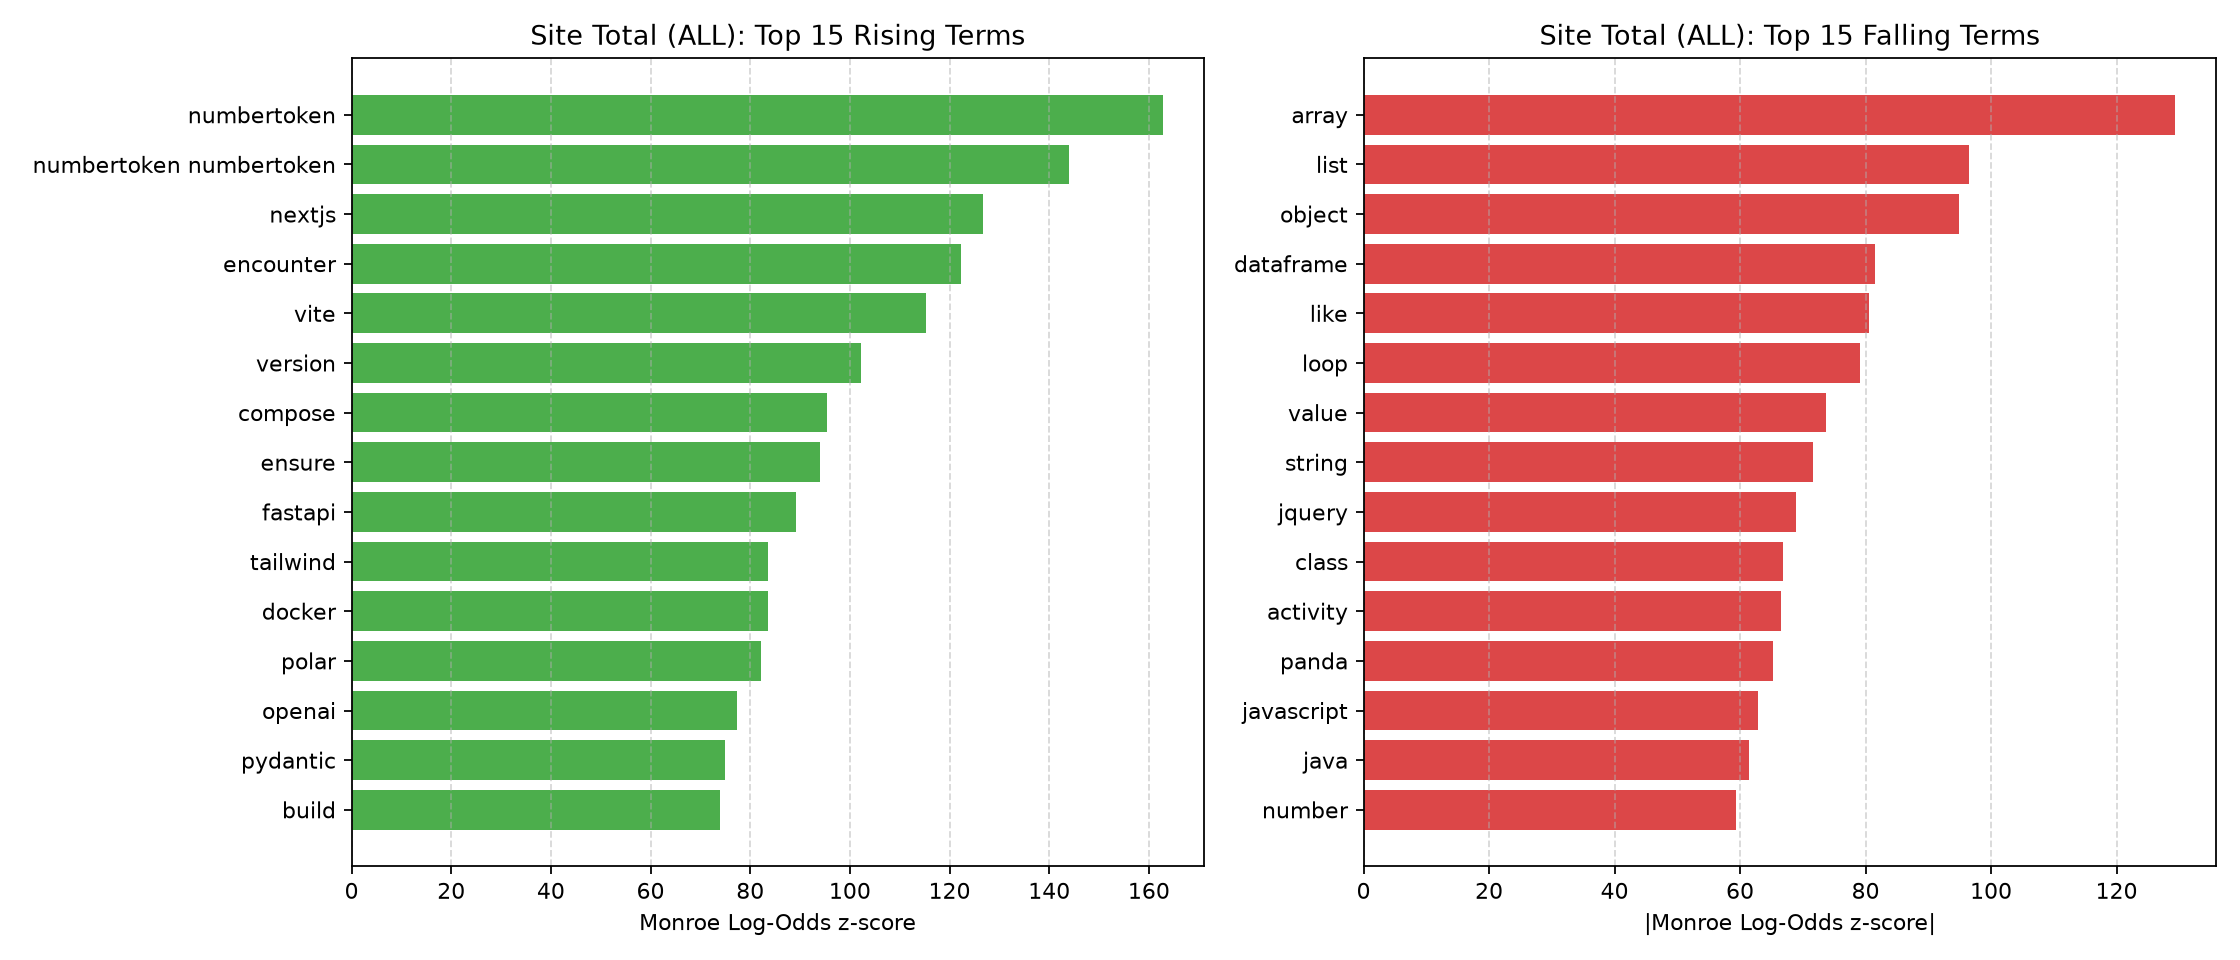

In [13]:
kw = pd.read_csv(TEXT / 'keywords_prepost.csv')
print('--- Top 10 Rising Terms (Post-AI Era) ---')
display(kw.query("tag_scope == 'ALL' and direction == 'rising'")[['term', 'z_score', 'freq_pre_pct', 'freq_post_pct']].head(10))
print('--- Top 10 Falling Terms (Pre-AI Era) ---')
display(kw.query("tag_scope == 'ALL' and direction == 'falling'")[['term', 'z_score', 'freq_pre_pct', 'freq_post_pct']].head(10))
display(Image(filename=str(TEXT / 'keywords_shift_all.png')))

### 7. Member 4 Findings and Viva Takeaways

In [14]:
print((ROOT / 'reports/review2/m4_findings.md').read_text())

# Member 4: Topic Modeling & Keyword Shift Findings

- **Model Selection & Semantic Quality**: NMF $k=10$ won under the pre-registered decision rule, achieving the highest NPMI coherence (+0.2175 on 20,000 held-out validation questions), 0.8000 topic diversity, and 1.0000 multi-seed stability. LDA failed semantic stability ($\le 0.28$) and yielded negative coherence ($-0.20$ to $-0.38$), proving NMF's superiority on sparse technical documents.
- **Offloading Routine Coding to AI**: Core syntax and basic data structures (Topic 8: arrays, loops, strings) dropped by **-16.96% relative community share** (pre: 20.49% to post: 17.02%, 95% bootstrap CI `[-0.0375, -0.0324]`). Pandas dataframe basic manipulation (Topic 1) similarly fell by **-10.74% relative share**, consistent with developers shifting simple lookups to AI assistants.
- **Persistence of Complex DevOps & Runtime Issues**: Docker containerization and cloud deployment (Topic 7) experienced a **+27.69% relative surge in share** (pr